# 02 · RQ2: Can a Model's Tier Be Classified From Its Features?
**Project:** Classifying the 2026 LLM API Market · ICT324 · Team Straw Hats · CRISP-DM phase: *Modeling (classification)*

### Research question and hypothesis
> **RQ2:** Can a model's tier be classified from its features, and which features decide it?
>
> **H2:** A classifier assigns tiers **better than a majority-class baseline** (H2a), and **non-performance features (provider, closed status)** rank among the **top deciding features** (H2b).

This notebook *tests* H2. It does not try to make it come out true. A weak or negative result is still an answer to RQ2, and the conclusion cell decides from the numbers.

### Method in one picture
```
rq1_tiers.csv (tier labels, notebook 01)  +  clean_models.csv (model specs, notebook 00)
  → join  → LEAKAGE GUARD: drop every price / benchmark column (tiers were built from them)
  → features in 3 groups:  Vendor/market | Capability | Time
  → baselines (majority, stratified random)
  → Decision Tree vs Random Forest vs XGBoost
        nested, repeated stratified 5-fold CV  (inner CV tunes, outer CV scores)
  → permutation test (is the score better than chance?)
  → confusion matrix  → SHAP + grouped permutation importance  → ablations
  → robustness: other targets (price band, performance band, Ward labels)
  → H2a / H2b verdicts
```

### The key design issue: circularity
RQ1 built the tiers from only two numbers: **log price** and **composite performance**. If we gave the classifier the price or a benchmark score, it would "rediscover" the clustering rule and score close to 100%, which tells us nothing. The real question for RQ2 is therefore:

> *Without looking at price or benchmark scores, can we tell which tier a model belongs to from **who makes it**, **what it can do**, and **when it came out**?*

We still run the price-based model once (Step 10), but only as a **ceiling** that shows what a "leaky" classifier would score. It is not evidence for H2.

### How to run in Google Colab
Run the cells in order. The setup cell asks you to upload `rq1_tiers.csv` (output of notebook 01) and `clean_models.csv` (output of notebook 00). `xgboost` and `shap` are preinstalled on Colab. If they are missing, the setup cell installs them. The full notebook takes a few minutes, mostly in Step 6 (nested CV) and Step 7 (permutation test).

## Step 1 · Setup
Libraries and fixed settings:
- **`SEED = 42`** is used everywhere (CV splits, forests, boosting, permutations), so every run gives the same numbers.
- **`N_REPEATS = 10`** repeats 5-fold CV ten times with different shuffles. With only 144 models, a single 5-fold split is noisy, and repeating it gives a mean **and** a spread (± SD).
- **`TOP_K = 3`** is the H2b criterion, fixed **before** looking at any results: a feature "ranks among the top deciding features" if it is in the top 3.

In [1]:
import os, sys, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import xgboost, shap
except ImportError:                                   # Colab normally has both
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost", "shap"], check=True)
    import xgboost, shap
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     permutation_test_score)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
SEED = 42
N_SPLITS, N_REPEATS = 5, 10       # outer CV: 5 folds × 10 repeats = 50 test folds
INNER_SPLITS = 3                  # inner CV for hyper-parameter tuning
N_PERMUTATIONS = 100              # label-shuffle test
TOP_K = 3                         # H2b criterion, fixed in advance
MIN_LAB_MODELS = 4                # labs with fewer models are pooled into "other"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    DATA_DIR = OUT_DIR = FIG_DIR = "."
    need = ["rq1_tiers.csv", "clean_models.csv"]
    if not all(os.path.exists(f) for f in need):
        print("Upload rq1_tiers.csv (notebook 01) and clean_models.csv (notebook 00):")
        files.upload()
else:
    DATA_DIR = OUT_DIR = "../data/processed"
    FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

tiers = pd.read_csv(os.path.join(DATA_DIR, "rq1_tiers.csv"))
models = pd.read_csv(os.path.join(DATA_DIR, "clean_models.csv"))
print("tiers:", tiers.shape, "| models:", models.shape,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__)

tiers: (144, 13) | models: (411, 33) | xgboost 3.4.1 | shap 0.54.1


/home/nyiyenaing/.cache/uv/archive-v0/0_VQbP75zPoscA7d/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2 · Build the dataset: one row per tiered model
The **target** is `tier_id` (T1–T7) from notebook 01. We join it to the model specs in `clean_models.csv` on `model_id`. Every tiered model should find its specs, because notebook 01 drew them from the same file.

Then we look at **class balance**. Seven classes from 144 models is small, and if one tier is much rarer than the others, a classifier can mostly ignore it. That is why we use **macro F1** (the average of per-tier F1, so every tier counts equally) as the main score, not plain accuracy.

In [2]:
tier_names = tiers.drop_duplicates("tier_id").set_index("tier_id").tier.sort_index()
df = tiers[["model_id", "tier_id", "tier", "hc_cluster", "log_price", "performance"]].merge(
    models, on="model_id", how="left", validate="one_to_one")
assert df.lab.notna().all(), "some tiered models have no specs"
print(f"models with a tier and specs: {len(df)}")

counts = df.tier_id.value_counts().sort_index()
show = pd.DataFrame({"tier": tier_names, "n": counts, "share": (counts / len(df)).round(3)})
print(show.to_string())
print(f"\nmajority tier = T{counts.idxmax()} ({counts.max()/len(df):.1%}) → a 'always say T{counts.idxmax()}' "
      f"rule already gets that accuracy")
print(f"smallest tier = T{counts.idxmin()} with {counts.min()} models → about "
      f"{counts.min()/N_SPLITS:.1f} test models per fold")

models with a tier and specs: 144
                                  tier   n  share
tier_id                                          
1          Low-price / Low-performance   6  0.042
2         Low-price / High-performance  10  0.069
3          Low-price / Mid-performance  15  0.104
4          Mid-price / Low-performance  32  0.222
5          Mid-price / Mid-performance  33  0.229
6         High-price / Mid-performance  25  0.174
7        High-price / High-performance  23  0.160

majority tier = T5 (22.9%) → a 'always say T5' rule already gets that accuracy
smallest tier = T1 with 6 models → about 1.2 test models per fold


**Reading the result:** the tiers are imbalanced. T1 (Low-price / Low-performance) has only 6 models, so each test fold contains about one of them, and T1's F1 will be very noisy. Keep this in mind when reading per-tier results.

## Step 3 · Leakage guard: remove everything the tiers were built from
A column **leaks** if it contains, directly or indirectly, the price or the benchmark performance that defined the tiers. We remove:

| Removed column(s) | Why |
|---|---|
| `log_price`, `*_price_per_1m` | price is one of the two clustering axes |
| `performance` | the other clustering axis |
| `n_benchmarks` | how often a model was benchmarked, closely tied to how its performance score was built |
| `hc_cluster`, `tier` | other forms of the label itself |
| `model_id`, `model_name`, `family`, `description`, `weights_url`, `license` | identifiers or free text. They would let the model memorise individual models instead of learning patterns. |

`log_price` and `performance` are kept **aside** (not as features) for the ceiling check in Step 10.

In [3]:
LEAKY = ["log_price", "performance", "min_input_price_per_1m", "median_input_price_per_1m",
         "min_output_price_per_1m", "median_output_price_per_1m", "n_benchmarks",
         "hc_cluster", "tier"]
IDS = ["model_id", "model_name", "family", "description", "weights_url", "license"]
print("removed as leaky:", LEAKY)
print("removed as identifiers/free text:", IDS)

removed as leaky: ['log_price', 'performance', 'min_input_price_per_1m', 'median_input_price_per_1m', 'min_output_price_per_1m', 'median_output_price_per_1m', 'n_benchmarks', 'hc_cluster', 'tier']
removed as identifiers/free text: ['model_id', 'model_name', 'family', 'description', 'weights_url', 'license']


## Step 4 · Engineer the features, in three meaningful groups
H2 is about **"non-performance" features**, so we organise the features by *what they describe*. Later we can then ask which **kind** of information decides the tier.

| Group | Features | Meaning |
|---|---|---|
| **Vendor / market** | `lab_*` (one-hot; labs with < 4 models pooled as `other`), `open_weights`, `n_providers` | *who* makes it, whether it is closed, and how many API hosts offer it |
| **Capability** | `reasoning`, `tool_call`, `attachment`, `temperature`, `input_image/audio/video/pdf`, `log_context`, `log_max_output` | *what* it can do (declared specs, **not** benchmark scores) |
| **Time** | `release_days` (days since 2023-01-01) | *when* it came out |

**H2's "provider and closed status"** correspond to **`lab`** (the model's maker) and **`open_weights`** (0 = closed). `n_providers` is a different thing: the number of companies that host the model. We keep it in the vendor/market group but do **not** count it as "provider" for H2b.

Cleaning decisions:
- `context_window` and `max_output_tokens` span several orders of magnitude, so we take **log10**.
- **Near-constant** flags (one value in > 95% of models) carry almost no information and are dropped automatically.
- `structured_output` (47% missing) and `knowledge_cutoff` (26% missing) are **dropped** rather than imputed, because guessing them would add noise.
- The lab one-hot block is treated as **one feature ("lab")** whenever we rank importance, so that lab is not split into 13 small pieces.

In [4]:
X_raw = pd.DataFrame(index=df.index)
lab_n = df.lab.value_counts()
df["lab_grouped"] = df.lab.where(df.lab.map(lab_n) >= MIN_LAB_MODELS, "other")
LAB_COLS = []
for lab in sorted(df.lab_grouped.unique()):
    col = f"lab_{lab}"; X_raw[col] = (df.lab_grouped == lab).astype(int); LAB_COLS.append(col)
X_raw["open_weights"] = df.open_weights.astype(int)
X_raw["n_providers"] = df.n_providers

CAP_FLAGS = ["reasoning", "tool_call", "attachment", "temperature",
             "input_image", "input_audio", "input_video", "input_pdf"]
for c in CAP_FLAGS:
    X_raw[c] = df[c].astype(int)
X_raw["log_context"] = np.log10(df.context_window)
X_raw["log_max_output"] = np.log10(df.max_output_tokens.clip(lower=1))
X_raw["release_days"] = (pd.to_datetime(df.release_date) - pd.Timestamp("2023-01-01")).dt.days

# drop near-constant binary flags (except lab dummies, which are handled as one block)
dominant = {c: X_raw[c].value_counts(normalize=True).iloc[0] for c in X_raw if c not in LAB_COLS}
dropped = [c for c, s in dominant.items() if s > 0.95]
X = X_raw.drop(columns=dropped)
print("dropped as near-constant (>95% one value):", {c: round(dominant[c], 3) for c in dropped})

GROUPS = {
    "Vendor":     LAB_COLS + ["open_weights", "n_providers"],
    "Capability": [c for c in CAP_FLAGS + ["log_context", "log_max_output"] if c in X],
    "Time":       ["release_days"],
}
# "features" for importance ranking: lab block = one feature, everything else itself
FEATURES = {"lab": LAB_COLS, **{c: [c] for c in X.columns if c not in LAB_COLS}}
GROUP_OF = {f: g for g, cols in GROUPS.items() for f in FEATURES if FEATURES[f][0] in cols}
H2_FEATURES = ["lab", "open_weights"]
assert X.isna().sum().sum() == 0
y = df.tier_id.values - 1                      # classes 0..6 (T1..T7) for XGBoost
print(f"X: {X.shape[0]} models × {X.shape[1]} columns ({len(FEATURES)} features after "
      f"grouping lab); labs kept: {[c[4:] for c in LAB_COLS]}")
print({g: len(c) for g, c in GROUPS.items()})

dropped as near-constant (>95% one value): {'tool_call': np.float64(0.979)}
X: 144 models × 25 columns (13 features after grouping lab); labs kept: ['alibaba', 'anthropic', 'deepseek', 'google', 'meta', 'minimax', 'mistral', 'moonshotai', 'openai', 'other', 'xai', 'xiaomi', 'zhipuai']
{'Vendor': 15, 'Capability': 9, 'Time': 1}


### 4b · Quick look: how do the features differ across tiers?
Before modelling, a plain description. The heatmap shows the **share of models with each flag** per tier, and the boxplots show the numeric features. Look for features that clearly change from tier to tier: those are what a classifier can use.

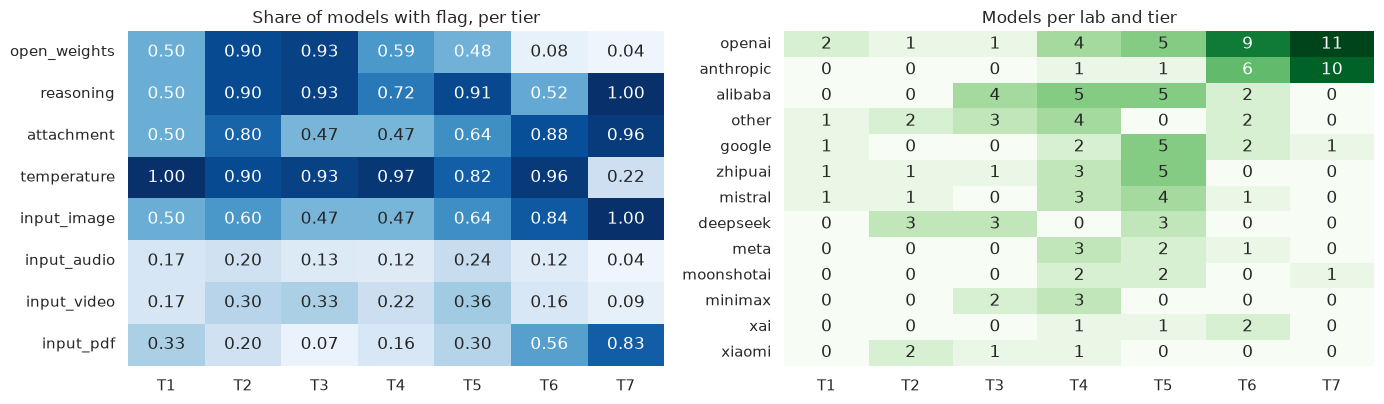

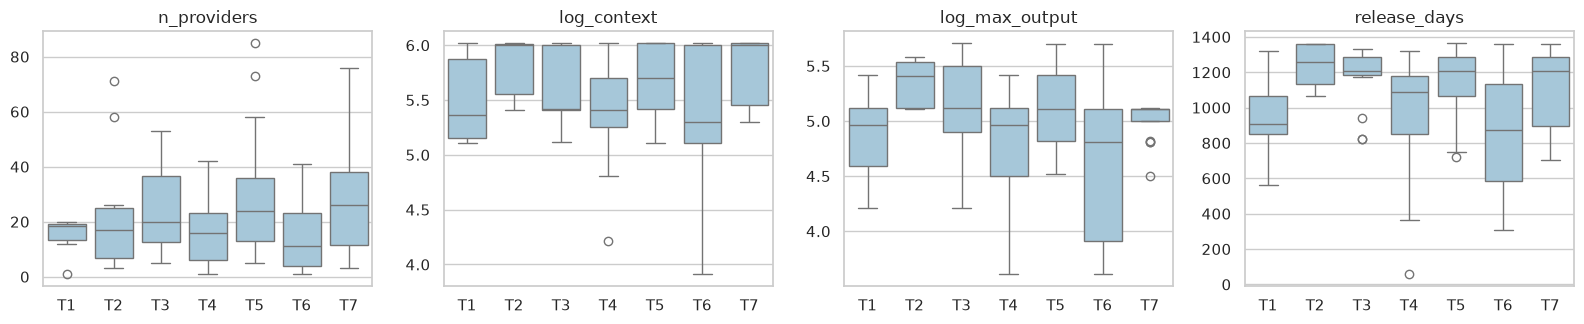

tier_id
T1      Low-price / Low-performance
T2     Low-price / High-performance
T3      Low-price / Mid-performance
T4      Mid-price / Low-performance
T5      Mid-price / Mid-performance
T6     High-price / Mid-performance
T7    High-price / High-performance


In [5]:
flag_cols = ["open_weights"] + [c for c in CAP_FLAGS if c in X]
share = X[flag_cols].groupby(df.tier_id).mean().T
share.columns = [f"T{t}" for t in share.columns]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(share, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Share of models with flag, per tier")
lab_tab = pd.crosstab(df.lab_grouped, df.tier_id)
lab_tab.columns = [f"T{t}" for t in lab_tab.columns]
sns.heatmap(lab_tab.loc[lab_tab.sum(axis=1).sort_values(ascending=False).index], annot=True, fmt="d",
            cmap="Greens", ax=ax[1], cbar=False)
ax[1].set_title("Models per lab and tier"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_flags_labs_by_tier.png"), dpi=150); plt.show()

num_cols = ["n_providers", "log_context", "log_max_output", "release_days"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, c in zip(ax, num_cols):
    sns.boxplot(x=df.tier_id.map(lambda t: f"T{t}"), y=X[c], ax=a, color="#9ecae1",
                order=[f"T{t}" for t in tier_names.index])
    a.set_title(c); a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_numeric_by_tier.png"), dpi=150); plt.show()
print(tier_names.rename(lambda t: f"T{t}").to_string())

**Reading the plots:**
- `open_weights` splits roughly along the **price axis**: the high-price tiers T6/T7 are almost all closed, while the low-price tiers T2/T3 are almost all open-weight.
- `release_days` separates **T6 from T7**: T6 (high price / mid performance) holds clearly older models. This matches the era-bias limitation noted in RQ1. Older models score lower percentiles against newer peers, so part of "T6" may simply be "older flagship".
- Labs are spread over several tiers. OpenAI, for example, appears in almost every tier, so lab alone cannot be a perfect predictor.

These are only marginal patterns. The next steps test whether they add up to reliable classification.

## Step 5 · Baselines: what does "no real knowledge" score?
H2a says *better than a majority-class baseline*, so we need that baseline measured **with the same CV**:
- **Majority:** always predicts the most common tier. Its accuracy equals that tier's share, and its macro F1 is very low because 6 of 7 tiers get F1 = 0.
- **Stratified random:** guesses tiers at random in their observed proportions. This is chance level for macro F1.

All models in this notebook are scored on the **same 50 outer folds** (`RepeatedStratifiedKFold`, 5 folds × 10 repeats, `SEED`), so differences come from the models, not from different splits.

In [6]:
outer = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
SPLITS = list(outer.split(X, y))

def score_fold(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro", labels=range(7), zero_division=0)}

fold_scores = {}       # model name -> DataFrame of per-fold scores
for name, est in [("Majority", DummyClassifier(strategy="most_frequent")),
                  ("Stratified random", DummyClassifier(strategy="stratified", random_state=SEED))]:
    rows = []
    for tr, te in SPLITS:
        m = clone(est).fit(X.iloc[tr], y[tr]); rows.append(score_fold(y[te], m.predict(X.iloc[te])))
    fold_scores[name] = pd.DataFrame(rows)
    print(f"{name:18s} accuracy = {fold_scores[name].accuracy.mean():.3f} ± {fold_scores[name].accuracy.std():.3f}"
          f" | macro F1 = {fold_scores[name].macro_f1.mean():.3f} ± {fold_scores[name].macro_f1.std():.3f}")

Majority           accuracy = 0.208 ± 0.003 | macro F1 = 0.049 ± 0.001


Stratified random  accuracy = 0.111 ± 0.014 | macro F1 = 0.075 ± 0.010


## Step 6 · Train and compare Decision Tree, Random Forest and XGBoost (nested CV)
**Why nested CV?** Each model has settings (hyper-parameters) such as tree depth. If we picked the best settings by looking at the same folds we report, the score would be optimistically biased, which is a real risk with only 144 models. Nested CV avoids this:
- **Outer loop** (50 folds): holds out a test fold the model never sees.
- **Inner loop** (3-fold CV on the training part only): tries each setting in a small grid and keeps the best by macro F1.
- The tuned model is then scored once on the outer test fold.

**Class imbalance:** DT and RF use `class_weight="balanced"`, and XGBoost gets the equivalent balanced `sample_weight`, so small tiers are not ignored.

The grids are deliberately small. With this little data, a big search mostly fits noise.

| Model | Why include it | Grid |
|---|---|---|
| Decision Tree | one readable tree, fully explainable | depth 2–6/none, min leaf 1/3/5 |
| Random Forest | many de-correlated trees, robust on small data | depth 6/none, max_features sqrt/0.5 |
| XGBoost | boosted trees, often strongest on tabular data | depth 2/3, learning rate 0.05/0.1 |

In [7]:
CANDIDATES = {
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                      {"max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 3, 5]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                             random_state=SEED, n_jobs=-1),
                      {"max_depth": [6, None], "max_features": ["sqrt", 0.5]}),
    "XGBoost":       (XGBClassifier(n_estimators=200, subsample=0.8, colsample_bytree=0.8,
                                    objective="multi:softprob", eval_metric="mlogloss",
                                    random_state=SEED, n_jobs=-1, verbosity=0),
                      {"max_depth": [2, 3], "learning_rate": [0.05, 0.1]}),
}

def fit_model(est, Xtr, ytr):
    """Fit with balanced weights (XGBoost has no class_weight, so pass sample_weight)."""
    if isinstance(est, XGBClassifier):
        return est.fit(Xtr, ytr, sample_weight=compute_sample_weight("balanced", ytr))
    return est.fit(Xtr, ytr)

chosen_params, oof_pred = {}, {}
for name, (est, grid) in CANDIDATES.items():
    rows, params, preds = [], [], np.full((N_REPEATS, len(y)), -1)
    for i, (tr, te) in enumerate(SPLITS):
        inner = StratifiedKFold(INNER_SPLITS, shuffle=True, random_state=SEED + i)
        gs = GridSearchCV(est, grid, scoring="f1_macro", cv=inner, n_jobs=1)
        if isinstance(est, XGBClassifier):
            gs.fit(X.iloc[tr], y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
        else:
            gs.fit(X.iloc[tr], y[tr])
        p = gs.predict(X.iloc[te]); preds[i // N_SPLITS, te] = p
        rows.append(score_fold(y[te], p)); params.append(str(gs.best_params_))
    fold_scores[name], oof_pred[name] = pd.DataFrame(rows), preds
    chosen_params[name] = pd.Series(params).value_counts()
    print(f"{name:14s} accuracy = {fold_scores[name].accuracy.mean():.3f} ± {fold_scores[name].accuracy.std():.3f}"
          f" | macro F1 = {fold_scores[name].macro_f1.mean():.3f} ± {fold_scores[name].macro_f1.std():.3f}"
          f" | most chosen: {chosen_params[name].index[0]} ({chosen_params[name].iloc[0]}/50)")

Decision Tree  accuracy = 0.330 ± 0.087 | macro F1 = 0.296 ± 0.077 | most chosen: {'max_depth': 6, 'min_samples_leaf': 1} (12/50)


Random Forest  accuracy = 0.372 ± 0.068 | macro F1 = 0.327 ± 0.064 | most chosen: {'max_depth': None, 'max_features': 0.5} (19/50)


XGBoost        accuracy = 0.393 ± 0.078 | macro F1 = 0.343 ± 0.072 | most chosen: {'learning_rate': 0.1, 'max_depth': 3} (15/50)


                   accuracy_mean  accuracy_sd  macro_f1_mean  macro_f1_sd  beats_majority_folds
Majority                   0.208        0.003          0.049        0.001                   0.0
Stratified random          0.111        0.014          0.075        0.010                   1.0
Decision Tree              0.330        0.087          0.296        0.077                   1.0
Random Forest              0.372        0.068          0.327        0.064                   1.0
XGBoost                    0.393        0.078          0.343        0.072                   1.0

best classifier by mean macro F1: XGBoost


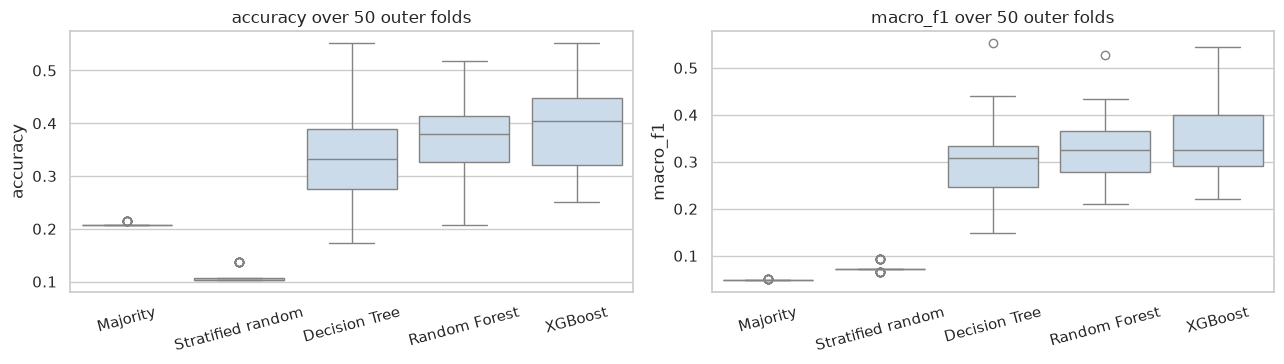

In [8]:
cv_table = pd.DataFrame({n: {"accuracy_mean": s.accuracy.mean(), "accuracy_sd": s.accuracy.std(),
                             "macro_f1_mean": s.macro_f1.mean(), "macro_f1_sd": s.macro_f1.std()}
                         for n, s in fold_scores.items()}).T
maj = fold_scores["Majority"].macro_f1.values
cv_table["beats_majority_folds"] = [np.mean(fold_scores[n].macro_f1.values > maj) for n in cv_table.index]
print(cv_table.round(3).to_string())

BEST = cv_table.drop(["Majority", "Stratified random"]).macro_f1_mean.idxmax()
print(f"\nbest classifier by mean macro F1: {BEST}")

long = pd.concat([s.assign(model=n) for n, s in fold_scores.items()])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, metric in zip(ax, ["accuracy", "macro_f1"]):
    sns.boxplot(data=long, x="model", y=metric, ax=a, color="#c6dbef")
    a.set_title(f"{metric} over 50 outer folds"); a.set_xlabel(""); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_cv_scores.png"), dpi=150); plt.show()

**Reading the result:** compare each classifier's box with the two baselines. The column `beats_majority_folds` gives the share of the 50 test folds where the classifier's macro F1 is higher than the majority rule's **on the same fold**. That paired view is fairer than comparing two means. Also look at the *size* of the score, not only whether it beats the baseline. With 7 tiers, a model can be "better than majority" and still mislabel most models.

## Step 7 · Is the best score better than chance? (label-permutation test)
Beating the baseline on average could still be luck. The **permutation test** asks: *if the tiers were assigned to models at random, how often would the classifier score this well?*
1. Shuffle the tier labels (this breaks any real link between features and tier).
2. Re-run 5-fold CV and record the macro F1.
3. Repeat `N_PERMUTATIONS` times. The **p-value** is the share of shuffled runs that score at least as well as the real labels.

For speed this uses the best model with its **most often chosen settings** from Step 6 (fixed, no re-tuning). Steps 8–11 use the same fixed model.

fixed model for Steps 7–11: XGBoost {'learning_rate': 0.1, 'max_depth': 3}


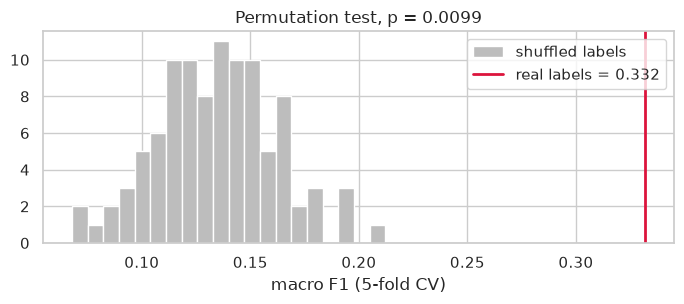

real macro F1 = 0.332 | shuffled: mean 0.134, max 0.212 | p = 0.0099  (smallest possible p = 0.0099)


In [9]:
import ast
best_params = ast.literal_eval(chosen_params[BEST].index[0])
BEST_EST = clone(CANDIDATES[BEST][0]).set_params(**best_params)
print(f"fixed model for Steps 7–11: {BEST} {best_params}")

perm_cv = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)
fit_params = ({"sample_weight": compute_sample_weight("balanced", y)}
              if isinstance(BEST_EST, XGBClassifier) else None)
real_score, perm_scores, p_value = permutation_test_score(
    BEST_EST, X, y, cv=perm_cv, scoring="f1_macro", n_permutations=N_PERMUTATIONS,
    random_state=SEED, n_jobs=-1, params=fit_params)

plt.figure(figsize=(7, 3.2))
plt.hist(perm_scores, bins=20, color="#bdbdbd", label="shuffled labels")
plt.axvline(real_score, color="crimson", lw=2, label=f"real labels = {real_score:.3f}")
plt.xlabel("macro F1 (5-fold CV)"); plt.legend(); plt.title(f"Permutation test, p = {p_value:.4f}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_permutation_test.png"), dpi=150); plt.show()
print(f"real macro F1 = {real_score:.3f} | shuffled: mean {perm_scores.mean():.3f}, "
      f"max {perm_scores.max():.3f} | p = {p_value:.4f}  (smallest possible p = {1/(N_PERMUTATIONS+1):.4f})")

**Reading the result:** if the red line lies far to the right of the grey histogram (small p, e.g. < 0.05), the features carry **real** information about the tier. If it falls inside the histogram, the "beats baseline" result could be chance.

## Step 8 · Where does the classifier go wrong? (confusion matrix)
We pool the **out-of-fold predictions** of the nested-CV best model over all 10 repeats (each model is predicted 10 times, once per repeat, always by a model that never saw it). Rows are the **true** tier and columns the **predicted** tier. Values are row shares, so the diagonal is the per-tier recall.

What to look for: are mistakes made between **neighbouring tiers** (same price band, different performance, or the reverse)? That tells us which axis the features "see".

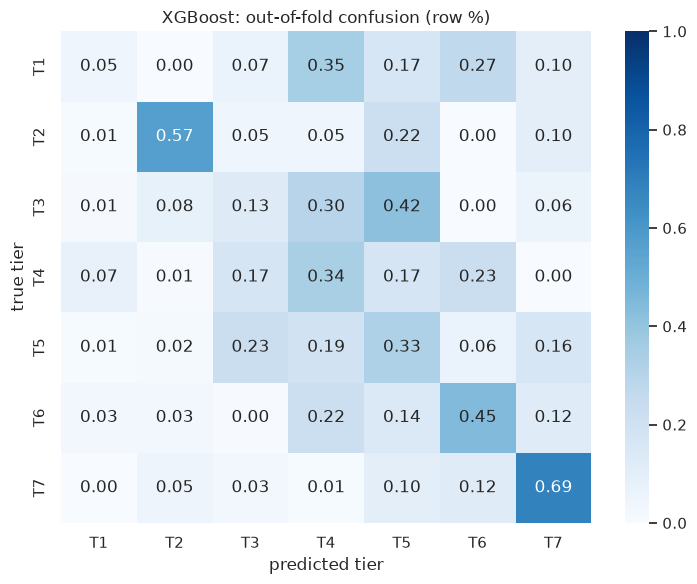

                             tier  precision  recall  f1-score
T1    Low-price / Low-performance       0.07    0.05      0.06
T2   Low-price / High-performance       0.59    0.57      0.58
T3    Low-price / Mid-performance       0.11    0.13      0.12
T4    Mid-price / Low-performance       0.36    0.34      0.35
T5    Mid-price / Mid-performance       0.34    0.33      0.33
T6   High-price / Mid-performance       0.45    0.45      0.45
T7  High-price / High-performance       0.59    0.69      0.63

errors: 60.7% of predictions | among errors: same price band 23.2%, same performance band 30.1%


In [10]:
P = oof_pred[BEST]
y_rep, p_rep = np.tile(y, N_REPEATS), P.ravel()
labels_txt = [f"T{t}" for t in tier_names.index]
cm = confusion_matrix(y_rep, p_rep, labels=range(7), normalize="true")
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels_txt, yticklabels=labels_txt,
            vmin=0, vmax=1)
plt.xlabel("predicted tier"); plt.ylabel("true tier"); plt.title(f"{BEST}: out-of-fold confusion (row %)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_confusion_matrix.png"), dpi=150); plt.show()

rep = pd.DataFrame(classification_report(y_rep, p_rep, labels=range(7), target_names=labels_txt,
                                         output_dict=True, zero_division=0)).T.iloc[:7]
rep["tier"] = tier_names.values
print(rep[["tier", "precision", "recall", "f1-score"]].round(2).to_string())

# how many errors stay within the same price band / performance band?
band = tier_names.str.extract(r"(\w+)-price / (\w+)-performance"); band.columns = ["price", "perf"]
pb, fb = band.price.values, band.perf.values
err = y_rep != p_rep
print(f"\nerrors: {err.mean():.1%} of predictions | among errors: same price band "
      f"{np.mean(pb[y_rep[err]] == pb[p_rep[err]]):.1%}, same performance band "
      f"{np.mean(fb[y_rep[err]] == fb[p_rep[err]]):.1%}")

**Reading the result:** the per-tier table shows which tiers are recognisable from specs alone and which are not. The last line splits the errors: if most errors stay in the **same price band**, the features mostly capture *price level* and miss *performance*, or the reverse if most stay in the same performance band.

## Step 9 · Which features decide the tier? (SHAP + permutation importance)
H2b is about **feature importance**. We use two complementary methods and **not** the default impurity importance of trees, which is known to favour continuous features (like `n_providers` or `release_days`) over binary ones (like `open_weights`).

1. **Grouped permutation importance (out-of-sample, primary).** In each CV test fold, we shuffle one feature (the whole lab block counts as one feature) and measure how much macro F1 **drops**. A large drop means the model relies on that feature to classify *unseen* models. We repeat this for the three **groups** (Vendor, Capability, Time).
2. **SHAP (in-sample, secondary).** SHAP splits each prediction into contributions from each feature. The mean |SHAP| over all models and tiers gives a global ranking, and the per-tier view shows *which tier* a feature helps to identify.

**H2b rule (fixed in Step 1):** H2b is supported if `lab` or `open_weights` is in the **top 3** of the feature ranking in **both** methods, partly supported if this holds in only one method, and not supported otherwise.

In [11]:
imp_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=5, random_state=SEED)
N_SHUFFLES = 10
rng = np.random.default_rng(SEED)
blocks = {**{f"[feature] {f}": c for f, c in FEATURES.items()},
          **{f"[group] {g}": c for g, c in GROUPS.items()}}
drops = {b: [] for b in blocks}
for tr, te in imp_cv.split(X, y):
    m = fit_model(clone(BEST_EST), X.iloc[tr], y[tr])
    Xte = X.iloc[te]; base = f1_score(y[te], m.predict(Xte), average="macro", labels=range(7), zero_division=0)
    for b, cols in blocks.items():
        for _ in range(N_SHUFFLES):
            Xp = Xte.copy(); idx = rng.permutation(len(Xp))
            Xp[cols] = Xte[cols].values[idx]          # shuffle the whole block together
            drops[b].append(base - f1_score(y[te], m.predict(Xp), average="macro",
                                            labels=range(7), zero_division=0))
perm_imp = pd.DataFrame({"drop_mean": {b: np.mean(v) for b, v in drops.items()},
                         "drop_sd": {b: np.std(v) for b, v in drops.items()}})
feat_perm = perm_imp[perm_imp.index.str.startswith("[feature]")].rename(lambda s: s[10:])
feat_perm = feat_perm.sort_values("drop_mean", ascending=False)
feat_perm["group"] = feat_perm.index.map(GROUP_OF); feat_perm["rank"] = range(1, len(feat_perm) + 1)
group_perm = perm_imp[perm_imp.index.str.startswith("[group]")].rename(lambda s: s[8:])
print("Permutation importance (drop in macro F1 when shuffled):")
print(feat_perm.round(3).to_string()); print(); print(group_perm.sort_values("drop_mean", ascending=False).round(3).to_string())

Permutation importance (drop in macro F1 when shuffled):
                drop_mean  drop_sd       group  rank
release_days        0.065    0.083        Time     1
temperature         0.061    0.050  Capability     2
log_max_output      0.048    0.084  Capability     3
open_weights        0.025    0.061      Vendor     4
n_providers         0.022    0.084      Vendor     5
input_pdf           0.005    0.047  Capability     6
input_video         0.001    0.022  Capability     7
lab                -0.001    0.045      Vendor     8
input_audio        -0.002    0.018  Capability     9
attachment         -0.003    0.036  Capability    10
input_image        -0.004    0.029  Capability    11
reasoning          -0.005    0.046  Capability    12
log_context        -0.007    0.062  Capability    13

            drop_mean  drop_sd
Capability      0.142    0.094
Vendor          0.076    0.087
Time            0.064    0.086


SHAP global ranking (mean |SHAP| over models and tiers):
                mean_abs_shap       group  rank
release_days           0.7648        Time     1
n_providers            0.6992      Vendor     2
open_weights           0.5217      Vendor     3
log_max_output         0.4722  Capability     4
lab                    0.3358      Vendor     5
log_context            0.2793  Capability     6
temperature            0.2243  Capability     7
input_pdf              0.2231  Capability     8
attachment             0.1671  Capability     9
reasoning              0.0771  Capability    10
input_image            0.0645  Capability    11
input_video            0.0358  Capability    12
input_audio            0.0128  Capability    13


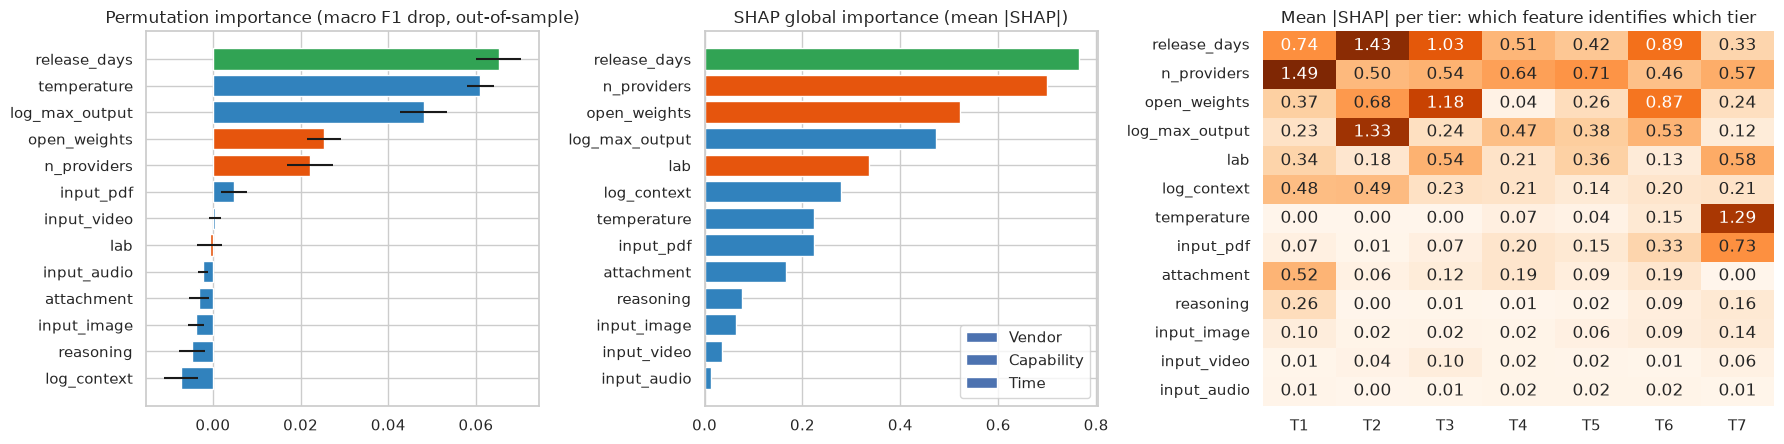

In [12]:
final = fit_model(clone(BEST_EST), X, y)
sv = shap.TreeExplainer(final).shap_values(X)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)   # → (models, columns, tiers)
abs_sv = np.abs(sv)
col_idx = {c: i for i, c in enumerate(X.columns)}
# lab block = sum of its columns' contributions (additive, so summing is valid)
per_tier = pd.DataFrame({f: abs_sv[:, [col_idx[c] for c in cols], :].sum(axis=1).mean(axis=0)
                         for f, cols in FEATURES.items()}, index=labels_txt).T
feat_shap = per_tier.mean(axis=1).sort_values(ascending=False).rename("mean_abs_shap").to_frame()
feat_shap["group"] = feat_shap.index.map(GROUP_OF); feat_shap["rank"] = range(1, len(feat_shap) + 1)
print("SHAP global ranking (mean |SHAP| over models and tiers):"); print(feat_shap.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.3]})
pal = {"Vendor": "#e6550d", "Capability": "#3182bd", "Time": "#31a354"}
ax[0].barh(feat_perm.index[::-1], feat_perm.drop_mean[::-1], xerr=feat_perm.drop_sd[::-1] / np.sqrt(25 * N_SHUFFLES),
           color=[pal[g] for g in feat_perm.group[::-1]])
ax[0].set_title("Permutation importance (macro F1 drop, out-of-sample)")
ax[1].barh(feat_shap.index[::-1], feat_shap.mean_abs_shap[::-1], color=[pal[g] for g in feat_shap.group[::-1]])
ax[1].set_title("SHAP global importance (mean |SHAP|)")
for g, c in pal.items(): ax[1].barh([], [], color=c, label=g)
ax[1].legend(loc="lower right")
sns.heatmap(per_tier.loc[feat_shap.index], cmap="Oranges", annot=True, fmt=".2f", ax=ax[2], cbar=False)
ax[2].set_title("Mean |SHAP| per tier: which feature identifies which tier")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_feature_importance.png"), dpi=150); plt.show()

In [13]:
# direction of effect for the two H2 features: does being closed / being lab X push toward a tier?
ow = col_idx["open_weights"]
direction = pd.DataFrame({t: [sv[X.open_weights == 0, ow, k].mean(), sv[X.open_weights == 1, ow, k].mean()]
                          for k, t in enumerate(labels_txt)}, index=["closed (0)", "open (1)"])
print("Mean SHAP of open_weights toward each tier (positive = pushes the model INTO that tier):")
print(direction.round(3).to_string())

Mean SHAP of open_weights toward each tier (positive = pushes the model INTO that tier):
               T1     T2     T3     T4     T5     T6     T7
closed (0) -0.454 -0.883 -1.679  0.046  0.272  0.481  0.125
open (1)    0.276  0.424  0.552 -0.026 -0.250 -1.357 -0.394


**Reading the result:**
- The two rankings answer slightly different questions. Permutation importance asks *what the model needs to classify new models*, and SHAP asks *what moved the predictions on the data it learned from*. If they agree, the ranking is trustworthy. If they disagree, report both.
- **Correlated features share credit.** `lab` and `open_weights` overlap (Anthropic and OpenAI are always closed), so shuffling one alone can look harmless while the other covers for it. The **group** rows and the ablations in Step 10 handle this by removing whole groups at once.
- The direction table shows *how* closed status acts. For example, a positive value for "closed" in a high-price tier means closed models are pushed into that tier.

## Step 10 · Ablations: train with feature groups removed or isolated
Importance scores can be distorted by correlated features. A more direct test is to **retrain without** a group (or **with only** that group) and see how the CV score changes. All runs use the same fixed model and the same splits (5 folds × 5 repeats).

| Run | Question it answers |
|---|---|
| all features | reference |
| − Vendor / − Capability / − Time | how much is lost when this kind of information is missing? |
| only Vendor / only Capability / only Time | how far does this kind of information get on its own? |
| only lab + open_weights | the **H2 features** on their own |
| **ceiling:** log_price only; log_price + performance | **circular**, shown only to calibrate the scale (these columns built the tiers) |

`− Time` doubles as the **era-bias check**: if removing release date costs a lot, part of what separates the tiers is simply model age.

(majority baseline macro F1 = 0.049)
                                             macro_f1_mean  macro_f1_sd  vs_all  vs_majority
all features                                         0.349        0.077   0.000        0.300
− Vendor                                             0.322        0.049  -0.027        0.272
− Capability                                         0.344        0.083  -0.005        0.295
− Time                                               0.326        0.090  -0.023        0.277
only Vendor                                          0.236        0.080  -0.113        0.187
only Capability                                      0.355        0.081   0.007        0.306
only Time                                            0.249        0.075  -0.100        0.200
only lab + open_weights (H2)                         0.216        0.063  -0.133        0.166
CEILING (circular): log_price                        0.395        0.074   0.046        0.345
CEILING (circular): log_price + p

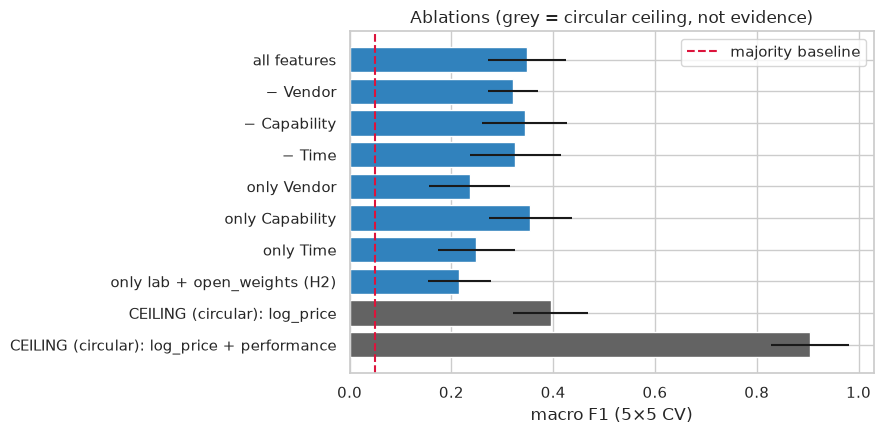

In [14]:
abl_cv = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=5, random_state=SEED).split(X, y))
def cv_macro_f1(Xa, est=None):
    est = est if est is not None else BEST_EST
    s = [f1_score(y[te], fit_model(clone(est), Xa.iloc[tr], y[tr]).predict(Xa.iloc[te]),
                  average="macro", labels=range(7), zero_division=0) for tr, te in abl_cv]
    return np.mean(s), np.std(s)

allc = list(X.columns)
runs = {"all features": allc}
for g, cols in GROUPS.items():
    runs[f"− {g}"] = [c for c in allc if c not in cols]
for g, cols in GROUPS.items():
    runs[f"only {g}"] = cols
runs["only lab + open_weights (H2)"] = LAB_COLS + ["open_weights"]

abl = {name: cv_macro_f1(X[cols]) for name, cols in runs.items()}
leak = pd.DataFrame({"log_price": df.log_price, "performance": df.performance})
abl["CEILING (circular): log_price"] = cv_macro_f1(leak[["log_price"]])
abl["CEILING (circular): log_price + performance"] = cv_macro_f1(leak)
abl = pd.DataFrame(abl, index=["macro_f1_mean", "macro_f1_sd"]).T
abl["vs_all"] = abl.macro_f1_mean - abl.loc["all features", "macro_f1_mean"]
maj_f1 = fold_scores["Majority"].macro_f1.mean()
abl["vs_majority"] = abl.macro_f1_mean - maj_f1
print(f"(majority baseline macro F1 = {maj_f1:.3f})"); print(abl.round(3).to_string())

plt.figure(figsize=(9, 4.5))
colors = ["#636363" if "CEILING" in i else "#3182bd" for i in abl.index]
plt.barh(abl.index[::-1], abl.macro_f1_mean[::-1], xerr=abl.macro_f1_sd[::-1], color=colors[::-1])
plt.axvline(maj_f1, color="crimson", ls="--", label="majority baseline"); plt.legend()
plt.xlabel("macro F1 (5×5 CV)"); plt.title("Ablations (grey = circular ceiling, not evidence)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "rq2_ablations.png"), dpi=150); plt.show()

**Reading the result:** a group matters if removing it causes a **clear drop** (larger than about one SD) **and** using it alone gets well above the baseline. The ceiling rows show how close a classifier gets when it is allowed to see the clustering inputs. The gap between "all features" and the ceiling is the part of the tier that specs alone **cannot** explain.

## Step 11 · Robustness: do the conclusions depend on how the target was defined?
The RQ1 tiers are one choice among several (k = 7, K-means, all eras). If RQ2's answer changes completely under a reasonable alternative target, we should say so. We re-run the fixed model (all non-leaky features) on:
- **Price band** (Low / Mid / High), the price half of the tier name;
- **Performance band** (Low / Mid / High), the performance half;
- **Ward labels** (`hc_cluster`), the hierarchical clustering from notebook 01 instead of K-means.

Each target is compared with its **own** majority baseline, since the number of classes differs.

In [15]:
targets = {"Tier (K-means, 7)": y,
           "Price band (3)": pd.Categorical(df.tier_id.map(dict(zip(tier_names.index, pb)))).codes,
           "Performance band (3)": pd.Categorical(df.tier_id.map(dict(zip(tier_names.index, fb)))).codes,
           "Ward clusters (hc_cluster)": pd.Categorical(df.hc_cluster).codes}
rob = []
for name, yt in targets.items():
    yt = np.asarray(yt); k = len(np.unique(yt))
    cvr = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=5, random_state=SEED).split(X, yt))
    def f1s(est):
        return [f1_score(yt[te], fit_model(clone(est), X.iloc[tr], yt[tr]).predict(X.iloc[te]),
                         average="macro", labels=range(k), zero_division=0) for tr, te in cvr]
    mdl, base = f1s(BEST_EST), f1s(DummyClassifier(strategy="most_frequent"))
    rob.append({"target": name, "classes": k, "model_macro_f1": np.mean(mdl), "sd": np.std(mdl),
                "majority_macro_f1": np.mean(base), "gain": np.mean(mdl) - np.mean(base),
                "beats_majority_folds": np.mean(np.array(mdl) > np.array(base))})
rob = pd.DataFrame(rob).set_index("target"); print(rob.round(3).to_string())

                            classes  model_macro_f1     sd  majority_macro_f1   gain  beats_majority_folds
target                                                                                                    
Tier (K-means, 7)                 7           0.349  0.077              0.049  0.300                   1.0
Price band (3)                    3           0.543  0.098              0.207  0.336                   1.0
Performance band (3)              3           0.529  0.126              0.224  0.305                   1.0
Ward clusters (hc_cluster)        7           0.342  0.084              0.055  0.287                   1.0


**Reading the result:** compare the **gain over majority** across targets. If the price band is much easier to predict than the performance band, the specs mainly reveal **how a model is priced** (closed vs open, maker), not **how well it performs**. If the Ward labels give a similar score to K-means, the RQ2 result does not hinge on the clustering algorithm.

## Step 12 · Save results
- `rq2_cv_results.csv`: CV scores of the baselines and the three classifiers (Step 6), plus the ablations and robustness runs.
- `rq2_feature_importance.csv`: permutation and SHAP rankings per feature (Step 9).
- Figures go to `reports/figures/rq2_*.png`.

In [16]:
res = pd.concat([cv_table.assign(section="model comparison (nested 5×10 CV)"),
                 abl.rename(columns={"macro_f1_mean": "macro_f1_mean", "macro_f1_sd": "macro_f1_sd"})
                    .assign(section=f"ablation ({BEST}, 5×5 CV)"),
                 rob.rename(columns={"model_macro_f1": "macro_f1_mean", "sd": "macro_f1_sd"})
                    .assign(section=f"robustness ({BEST}, 5×5 CV)")])
res.index.name = "run"
res.to_csv(os.path.join(OUT_DIR, "rq2_cv_results.csv"))
imp = feat_perm[["group", "drop_mean", "drop_sd", "rank"]].rename(
    columns={"drop_mean": "perm_f1_drop", "drop_sd": "perm_f1_drop_sd", "rank": "perm_rank"}).join(
    feat_shap[["mean_abs_shap", "rank"]].rename(columns={"rank": "shap_rank"}))
imp.index.name = "feature"
imp.to_csv(os.path.join(OUT_DIR, "rq2_feature_importance.csv"))
print("saved rq2_cv_results.csv", res.shape, "and rq2_feature_importance.csv", imp.shape)
if IN_COLAB:
    files.download("rq2_cv_results.csv"); files.download("rq2_feature_importance.csv")

saved rq2_cv_results.csv (19, 11) and rq2_feature_importance.csv (13, 6)


## Step 13 · Conclusion: verdicts computed from the numbers
The verdicts below follow the rules stated **before** the analysis:
- **H2a** is SUPPORTED if the best classifier's mean macro F1 exceeds the majority baseline **and** the permutation test gives p < 0.05. It is NOT supported otherwise.
- **H2b** is SUPPORTED if `lab` or `open_weights` is in the top 3 of **both** rankings (permutation and SHAP), PARTIAL if in only one, and NOT supported if in neither.

In [17]:
best_f1 = cv_table.loc[BEST, "macro_f1_mean"]
h2a = (best_f1 > maj_f1) and (p_value < 0.05)
top_perm = list(feat_perm.index[:TOP_K]); top_shap = list(feat_shap.index[:TOP_K])
in_perm = any(f in top_perm for f in H2_FEATURES); in_shap = any(f in top_shap for f in H2_FEATURES)
h2b = "SUPPORTED" if (in_perm and in_shap) else "PARTIAL" if (in_perm or in_shap) else "NOT supported"

print(f"Models: {len(df)} tiered LLMs, {len(FEATURES)} non-leaky features ({X.shape[1]} columns)")
print(cv_table[["accuracy_mean", "macro_f1_mean", "macro_f1_sd", "beats_majority_folds"]].round(3).to_string())
print(f"\nBest: {BEST}, macro F1 {best_f1:.3f} vs majority {maj_f1:.3f} "
      f"(×{best_f1/maj_f1:.1f}); permutation p = {p_value:.4f}")
print(f"H2a (beats majority baseline): {'SUPPORTED' if h2a else 'NOT supported'}")
print(f"\nTop-{TOP_K} permutation: {top_perm}")
print(f"Top-{TOP_K} SHAP:        {top_shap}")
print(f"Rank of H2 features (perm / SHAP): " +
      ", ".join(f"{f} {feat_perm.loc[f,'rank']}/{feat_shap.loc[f,'rank']}" for f in H2_FEATURES))
print(f"H2b (provider/closed status among top-{TOP_K}): {h2b}")
print(f"\nGroup ablations (macro F1 change when removed): " +
      ", ".join(f"{g} {abl.loc['− '+g,'vs_all']:+.3f}" for g in GROUPS))
print(f"Ceiling with price+performance (circular): {abl.loc['CEILING (circular): log_price + performance','macro_f1_mean']:.3f}")

Models: 144 tiered LLMs, 13 non-leaky features (25 columns)
                   accuracy_mean  macro_f1_mean  macro_f1_sd  beats_majority_folds
Majority                   0.208          0.049        0.001                   0.0
Stratified random          0.111          0.075        0.010                   1.0
Decision Tree              0.330          0.296        0.077                   1.0
Random Forest              0.372          0.327        0.064                   1.0
XGBoost                    0.393          0.343        0.072                   1.0

Best: XGBoost, macro F1 0.343 vs majority 0.049 (×7.0); permutation p = 0.0099
H2a (beats majority baseline): SUPPORTED

Top-3 permutation: ['release_days', 'temperature', 'log_max_output']
Top-3 SHAP:        ['release_days', 'n_providers', 'open_weights']
Rank of H2 features (perm / SHAP): lab 8/5, open_weights 4/3
H2b (provider/closed status among top-3): PARTIAL

Group ablations (macro F1 change when removed): Vendor -0.027, Capabilit

### Answer to RQ2
*(Filled in from the executed results; see the cell outputs above.)*

**Partly. Specs predict a model's tier clearly better than chance, but far from reliably. And what decides the tier is mainly *when* the model was released and *how it is offered*, not the maker's name.**

**H2a: SUPPORTED, but the effect is modest.** Using only non-price, non-benchmark features, all three classifiers beat the majority rule in all 50 test folds. Macro F1 by model:

| Model | Macro F1 (nested 5×10 CV) | Accuracy |
|---|---|---|
| Majority baseline | 0.05 | 0.21 |
| Stratified random | 0.08 | 0.11 |
| Decision Tree | 0.30 ± 0.08 | 0.33 |
| Random Forest | 0.33 ± 0.06 | 0.37 |
| **XGBoost** | **0.34 ± 0.07** | **0.39** |

The permutation test gives p ≈ 0.01, the smallest value possible with 100 shuffles. Shuffled labels never scored above 0.21. Even so, about 60% of models are still misclassified, and the three algorithms overlap within one SD, so no algorithm is clearly the best.
- T7 (high price / high performance, F1 0.63) and T2 (cheap open-weight high performers, F1 0.58) are recognisable from specs. T1 and T3 are essentially not recognisable (F1 ≤ 0.12).
- For comparison, **log price alone** (circular) reaches only 0.40, so specs carry almost as much tier information as the price itself. The tier becomes almost fully predictable (0.90) only once performance is added. The **performance half of the tier is what the specs cannot see.**

**H2b: PARTIAL.** Rules fixed in advance: `lab` or `open_weights` in the top 3 of both rankings.
- **Closed status (`open_weights`)** is rank 3 in SHAP and rank 4 in permutation importance. Its direction is clear: being closed pushes models toward T6/T5/T7 and away from T2/T3. It acts mainly on the **price** side of the tier.
- **Provider/lab** is **not** a top feature (rank 5 in SHAP, rank 8 in permutation). Lab and open_weights together reach only macro F1 0.22 on their own. Once the other specs are known, knowing the maker adds little.
- The most consistent top feature is **release date** (rank 1 in both methods). This matches RQ1's era bias: T6 "high price / mid performance" is largely older flagship models. API traits that describe *how* a model is offered come next: `temperature` (reasoning-style models often lock it), `log_max_output` and `n_providers`.
- Group view: removing any one group costs little (−0.03 or less), because the groups overlap. Capability features alone already reach the full score. Shuffling all capability features together hurts most (−0.14). So the deciding information is spread over correlated specs, not held by a single "provider" signal.

**Robustness:** the same model reaches macro F1 ≈ 0.54 on the 3-class price band and ≈ 0.53 on the performance band (each vs a majority rule of about 0.21), and 0.34 on the Ward tiers. The conclusions do not depend on the clustering algorithm.

**What this means for the project:** spec-based tier assignment can serve as a rough first guess for a new model with no benchmark scores yet (useful for RQ4's filters), but not as a replacement for benchmarks. The importance of release date is a warning for RQ1: part of what separates the tiers may be model age, so re-running RQ1 on recent models only (the era-bias fix) and then repeating this notebook is a sensible next check.

### Limitations
- **Small sample:** 144 models in 7 classes. T1 has only 6 models, so per-tier scores for small tiers have wide uncertainty. Repeated CV reduces, but cannot remove, this noise.
- **Labels inherit RQ1's choices:** the tiers depend on k = 7, the composite performance score and its era bias. A different tiering (e.g. recent models only) could change RQ2's answer. Step 11 checks only part of this.
- **Correlated features:** lab, open-weight status and release date overlap. Importance is shared among them, so "which feature decides" is better answered at the **group** level (Steps 9–10) than by single ranks.
- **Explanatory, not causal:** features that predict a tier (e.g. closed status → high price) describe market structure. They do not show that a feature *causes* the price or the performance.
- **Snapshot:** specs and tiers reflect the data up to Oct 2026. New releases may shift the boundaries.